<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m10-4-two-factors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Two Factors: Interaction and Simpson's Paradox

With two factors, a two-way ANOVA answers questions that two separate one-way analyses cannot. Part A shows an **interaction**: the effect of one factor depends on the other. Part B shows how ignoring a second factor can **reverse** a comparison.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## Part A. Interaction

What the two possibilities look like:

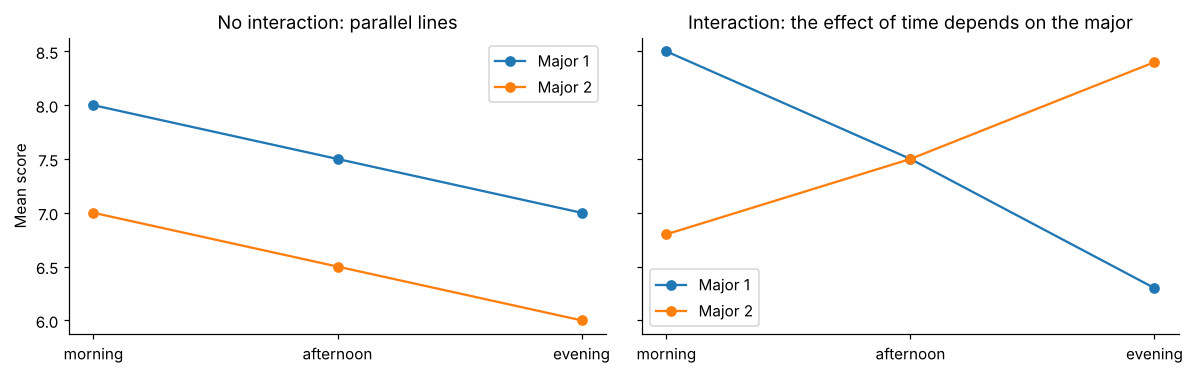

In [ ]:
order = ["morning", "afternoon", "evening"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
axes[0].plot(order, [8, 7.5, 7], marker="o", label="Major 1"); axes[0].plot(order, [7, 6.5, 6], marker="o", label="Major 2")
axes[0].set_title("No interaction: parallel lines"); axes[0].set_ylabel("Mean score"); axes[0].legend()
axes[1].plot(order, [8.5, 7.5, 6.3], marker="o", label="Major 1"); axes[1].plot(order, [6.8, 7.5, 8.4], marker="o", label="Major 2")
axes[1].set_title("Interaction: the effect of time depends on the major"); axes[1].legend()
plt.tight_layout(); plt.show()

### Example: the same 90 scores, now with majors

These are the 90 test scores from notebook 10.1, now with the major of each student: entrepreneurship or finance. In 10.1, the section time made no significant difference (p = 0.25).

In [ ]:
majors = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/two_way_anova_simpson.csv")
cell_means = majors.pivot_table(values="score", index="time_of_day", columns="major", aggfunc="mean").loc[order]
cell_means.round(2)

major,entrepreneurship,finance
time_of_day,,
morning,8.9000,6.9300
afternoon,7.4300,7.5700
evening,6.2000,8.5000


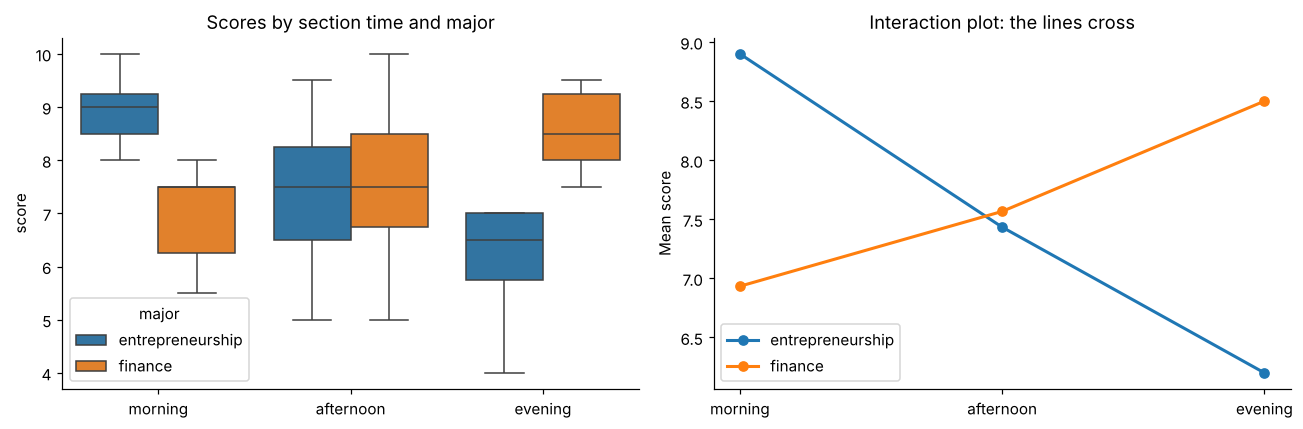

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=majors, x="time_of_day", y="score", hue="major", order=order, ax=axes[0])
axes[0].set_title("Scores by section time and major"); axes[0].set_xlabel("")
for m in cell_means.columns: axes[1].plot(order, cell_means[m], marker="o", lw=2, label=m)
axes[1].set_title("Interaction plot: the lines cross"); axes[1].set_ylabel("Mean score"); axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
model_a = ols("score ~ C(time_of_day) * C(major)", data=majors).fit()
sm.stats.anova_lm(model_a, typ=2)

,sum_sq,df,F,PR(>F)
C(time_of_day),5.1722,2.0000,2.3664,0.1000
C(major),0.5444,1.0000,0.4982,0.4823
C(time_of_day):C(major),68.2722,2.0000,31.2357,0.0000
Residual,91.8000,84.0000,NaN,NaN


How to read the table:

- `C(time_of_day)` and `C(major)` are the **main effects**: the effect of each factor, averaged over the other.
- `C(time_of_day):C(major)` is the **interaction**. Its p-value is tiny: the effect of the section time differs by major.

When the interaction is significant, main effects are hard to interpret on their own. The main effect of section time is not significant here, but section time matters a lot: entrepreneurship students do best in the morning, finance students in the evening, and the two effects cancel out on average.

**Question to you:** a department chair sees only the one-way analysis from 10.1 and concludes that the section time does not matter. What would you tell her?

## Part B. When a comparison reverses: Simpson's paradox

A business school compares exam scores in morning and evening sections of the same course. Students chose their own sections. The data are synthetic.

In [ ]:
sections = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/section_scores_simpson.csv")
sections.groupby("section_time")["score"].agg(["count", "mean"])

,count,mean
section_time,,
evening,50,7.8400
morning,50,7.4100


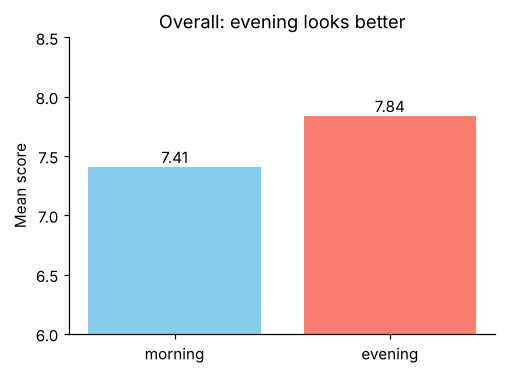

In [ ]:
tp = {"morning": "skyblue", "evening": "salmon"}
overall = sections.groupby("section_time")["score"].mean()[["morning", "evening"]]
plt.figure(figsize=(5, 3.5))
plt.bar(overall.index, overall, color=[tp[s] for s in overall.index])
for i, v in enumerate(overall): plt.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.ylim(6, 8.5); plt.ylabel("Mean score"); plt.title("Overall: evening looks better"); plt.show()

In [ ]:
evening = sections.loc[sections["section_time"] == "evening", "score"]
morning = sections.loc[sections["section_time"] == "morning", "score"]
t_stat, p_value = stats.ttest_ind(evening, morning)
print(f"Evening minus morning: {evening.mean() - morning.mean():.2f}, p-value = {p_value:.3f}")

Evening minus morning: 0.43, p-value = 0.162


The difference favors the evening, though it is not significant. Now split the comparison by major.

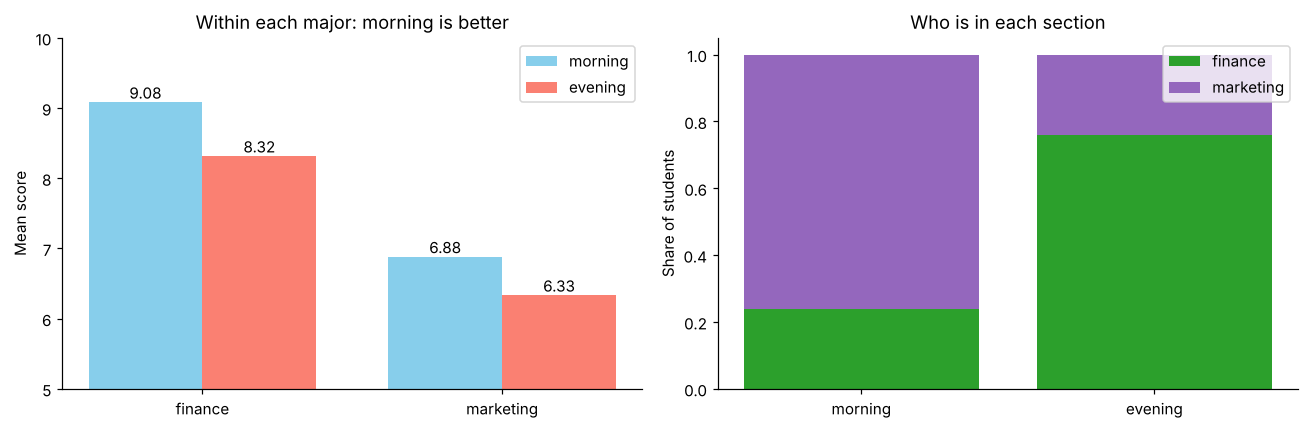

In [ ]:
within = sections.pivot_table(values="score", index="major", columns="section_time", aggfunc="mean")[["morning", "evening"]]
counts = pd.crosstab(sections["major"], sections["section_time"])[["morning", "evening"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(2); w = 0.38
for j, s in enumerate(["morning", "evening"]):
    axes[0].bar(x + (j - 0.5) * w, within[s], w, color=tp[s], label=s)
    for i, v in enumerate(within[s]): axes[0].text(i + (j - 0.5) * w, v, f"{v:.2f}", ha="center", va="bottom")
axes[0].set_xticks(x); axes[0].set_xticklabels(within.index); axes[0].set_ylim(5, 10)
axes[0].set_title("Within each major: morning is better"); axes[0].set_ylabel("Mean score"); axes[0].legend()
share = counts / counts.sum()
axes[1].bar(["morning", "evening"], share.loc["finance"], color="tab:green", label="finance")
axes[1].bar(["morning", "evening"], share.loc["marketing"], bottom=share.loc["finance"], color="tab:purple", label="marketing")
axes[1].set_title("Who is in each section"); axes[1].set_ylabel("Share of students"); axes[1].legend()
plt.tight_layout(); plt.show()

Within each major, **morning** students score higher. The overall comparison points the other way because most evening students are finance majors, and finance majors score higher in both section times. The overall comparison mixes the effect of the section time with the effect of the major.

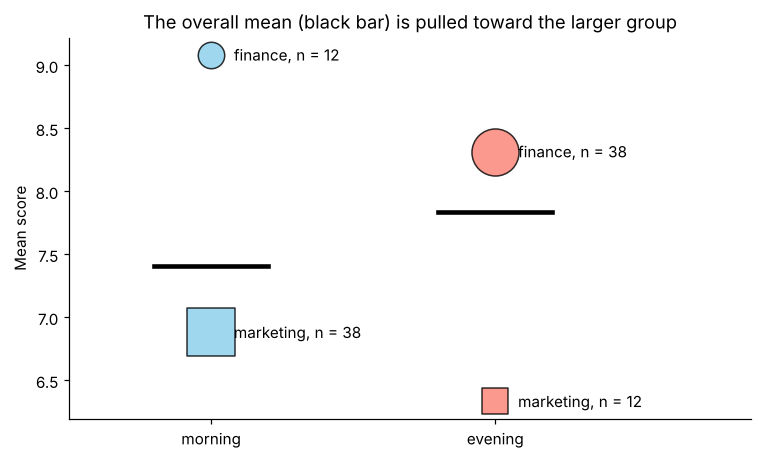

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, s in enumerate(["morning", "evening"]):
    for mj, mk in zip(["finance", "marketing"], ["o", "s"]):
        ax.scatter(j, within.loc[mj, s], s=counts.loc[mj, s] * 25, color=tp[s], edgecolor="black", marker=mk, alpha=0.8)
        ax.text(j + 0.08, within.loc[mj, s], f"{mj}, n = {counts.loc[mj, s]}", va="center")
    ax.plot([j - 0.2, j + 0.2], [overall[s]] * 2, color="black", lw=3)
ax.set_xticks([0, 1]); ax.set_xticklabels(["morning", "evening"]); ax.set_xlim(-0.5, 1.9)
ax.set_ylabel("Mean score"); ax.set_title("The overall mean (black bar) is pulled toward the larger group")
plt.show()

A two-way ANOVA compares the section times **within** each major.

In [ ]:
model_b = ols("score ~ C(section_time) + C(major)", data=sections).fit()
sm.stats.anova_lm(model_b, typ=2)

,sum_sq,df,F,PR(>F)
C(section_time),7.8947,1.0000,5.1662,0.0252
C(major),79.8347,1.0000,52.2428,0.0000
Residual,148.2303,97.0000,NaN,NaN


Once major is taken into account, the section time is significant at α = 0.05, in the opposite direction to the overall comparison: morning sections do better.

This is **Simpson's paradox**: a comparison that holds within every subgroup reverses when the subgroups are combined. It happens when the groups we compare contain different mixes of a variable that also affects the response. Here the major is a confounder: it affects both the choice of section and the score. In Module 12 you will see the same reversal in a regression, when a coefficient changes sign after another variable is added.

**Question to you:** the dean wants to move more courses to the evening because "evening students score higher". What would you tell the dean? Would randomly assigning students to sections settle the question?